In [1]:
from src.missing_data_generator import MissingDataGenerator
from src.gaussian_mixture import GaussianMixtureMAR
import numpy as np
import torch
from src.metrics import energy_distance_faster

from joblib import Parallel, delayed
import matplotlib.pyplot as plt

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [ ]:
n = 2000
d = 20
n_pat = 5
k_range = (15,25)
eps_vals = [None,0.0, 0.1, 0.5, 0.9]
B = 50

In [ ]:
distr = 'gaussian_mixture'
k=20

#distr = 'logistic'

if distr == 'gaussian_mixture':
            mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
            sigma0 = torch.rand((k, d)) * 2 # (0, 2)
            pi0 = torch.rand(k) + 0.1
            pi0 = pi0 / pi0.sum()
            mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr=distr,mu=mu0, sigma=sigma0, pi=pi0) # the patterns is sampled once in the init
else:
            mdg = MissingDataGenerator(n=n, d=d, n_pat=n_pat, seed=1, distr=distr) # the patterns is sampled once in the init


import numpy as np
import torch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

def sample_kde(X, n_samples, bandwidth="scott", shrink=True, seed=None):
    """
    Fit an isotropic Gaussian KDE to X (torch tensor, n x d) and draw n_samples.

    bandwidth: "scott", "silverman", "cv" (cross-validated), or a float.
    """
    X_np = X.detach().cpu().numpy()

    mu = X_np.mean(axis=0)
    sd = X_np.std(axis=0, ddof=1)
    sd[sd == 0] = 1.0
    Z = (X_np - mu) / sd

    if bandwidth == "cv":
        grid = GridSearchCV(
            KernelDensity(kernel="gaussian"),
            {"bandwidth": np.logspace(-1.5, 0.5, 20)},
            cv=KFold(5, shuffle=True, random_state=seed),
        )
        grid.fit(Z)
        kde = grid.best_estimator_
    else:
        kde = KernelDensity(kernel="gaussian", bandwidth=bandwidth).fit(Z)

    h = kde.bandwidth_
    Z_new = kde.sample(n_samples, random_state=seed)
    if shrink:
        # Z has mean 0 and unit variance, so this restores Var = 1 per column
        Z_new = Z_new / np.sqrt(1.0 + h**2)

    X_new = Z_new * sd + mu
    return torch.as_tensor(X_new, dtype=X.dtype, device=X.device)


def job(
        k_range: tuple = None,
        eps: int = None,
):
    X = mdg.get_X()
    Xtest = mdg.get_X()
    n = X.shape[0]

    if eps is None:
        # Baseline: KDE fitted on the complete data, no amputation, no model
        Xtilde = sample_kde(X, n, bandwidth="scott")
    else:
        _, M = mdg.get_M_ampute_eps(X, eps=eps)
        model = GaussianMixtureMAR(k_range=k_range)
        model.fit(X, M)
        Xtilde = model.sample(n)[0]

    return energy_distance_faster(Xtest, Xtilde, scale=True).item()


In [ ]:
#results = Parallel(n_jobs=4)(
#    delayed(job)(k_range=k_range, eps=eps)
#    for _ in range(B)
#    for eps in eps_vals
#)
from tqdm.auto import tqdm

results = list(tqdm(
    Parallel(n_jobs=5, return_as="generator")(
        delayed(job)(k_range=k_range, eps=eps)
        for _ in range(B)
        for eps in eps_vals
    ),
    total=B * len(eps_vals),
))

results = np.asarray(results).reshape(B, -1)


In [ ]:
np.save(f"results/density_estimation_{n_pat}_{distr}_patterns_{B}_B.npy", results)

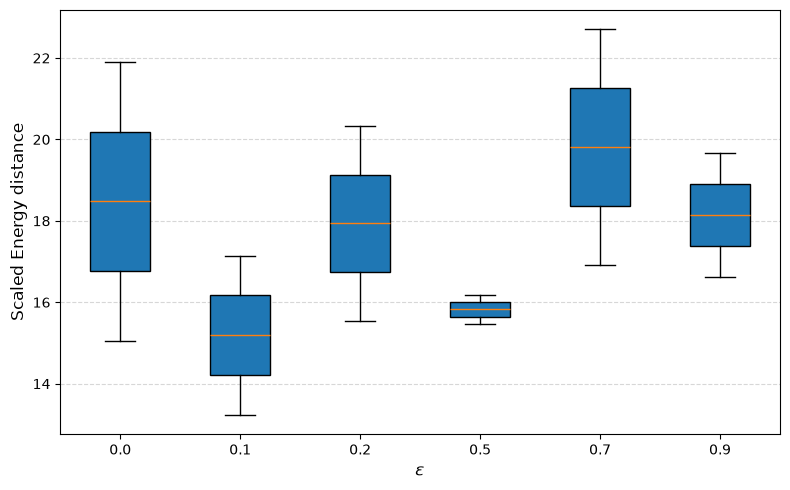

In [ ]:
import matplotlib.pyplot as plt

kde_results = results[:, 0]      # KDE column (eps=None)
box_results = results[:, 1:]     # the six eps columns
kde_mean = kde_results.mean()    # ≈ 94.2 for your numbers

# eps_vals must now have 6 entries (without None), e.g. eps_vals = eps_list

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(box_results, tick_labels=eps_vals[1:], patch_artist=True)

ax.axhline(
    kde_mean,
    color="crimson",
    linewidth=3,
    label=f"KDE (mean = {kde_mean:.3g})",
    zorder=3,
)

ax.set_ylabel("Scaled Energy distance", fontsize=12)
ax.set_xlabel(r"$\epsilon$", fontsize=12)
ax.tick_params(axis="both", labelsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(fontsize=10)

fig.tight_layout()
plt.savefig(
    f"results/density_estimation_{n_pat}_{distr}_patterns_{B}_B.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()